# Лабораторная работа №1
## Поэлементные преобразования изображений

### Используемые библиотеки

- `numpy` — работа с массивами изображения, вычисления, гистограммы, `np.cumsum` и `np.where`.
- `matplotlib.pyplot` — вывод изображений, гистограмм и графиков функций преобразования.
- `skimage.exposure`, отсюда стандартная эквализация, с которой сравнивается самописный алгоритм.

Для 8-битного полутонового изображения яркость принимает значения от **0 до 255**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import io, exposure

FILE = "02_apss.tif"
img = io.imread(FILE)

# Если изображение цветное — переводим в полутоновое без готовой функции обработки
if img.ndim == 3:
    img = np.round(
        0.299 * img[:, :, 0] +
        0.587 * img[:, :, 1] +
        0.114 * img[:, :, 2]
    ).astype(np.uint8)

img = img.astype(np.uint8)

print("Размер:", img.shape)
print("Диапазон:", img.min(), "-", img.max())

Размер: (512, 512)
Диапазон: 12 - 249


# I. Пороговая обработка

### Гистограмма

Гистограмма показывает количество пикселей каждого уровня яркости.

При 256 уровнях `hist` — одномерный массив из **256 элементов**. Если используется

```python
hist, bins = np.histogram(..., bins=256, range=(0, 256))
```

то `bins` содержит **257 границ**:

`0, 1, 2, ..., 255, 256`.

Нормированная гистограмма получается делением на общее число пикселей:

$$
p(k)=\frac{h(k)}{N},
$$

и сумма её элементов равна 1.

## Пороговая обработка

Пороговая обработка разделяет пиксели на два класса:

$$
g(f)=
\begin{cases}
255,&f\ge f_0,\\
0,&f<f_0.
\end{cases}
$$

`f0` — выбранный порог. `np.where()` позволяет применить условие сразу ко всему массиву без цикла.

После преобразования изображение является бинарным и содержит только два уровня яркости: **0 и 255**. При увеличении порога белых пикселей становится меньше, при уменьшении — больше.

Порог f0 = 106


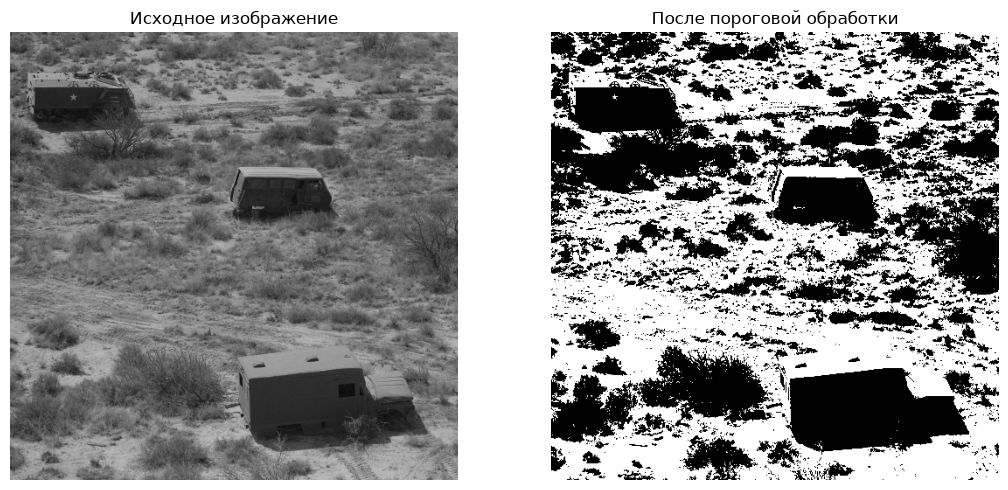

In [2]:
hist0, bins0 = np.histogram(img.ravel(), bins=256, range=(0, 256))
f0 = int(np.mean(img))

binary = np.where(img >= f0, 255, 0).astype(np.uint8)

print("Порог f0 =", f0)

fig, ax = plt.subplots(1, 2, figsize=(11, 5))

ax[0].imshow(img, cmap="gray", vmin=0, vmax=255)
ax[0].set_title("Исходное изображение")
ax[0].axis("off")

ax[1].imshow(binary, cmap="gray", vmin=0, vmax=255)
ax[1].set_title("После пороговой обработки")
ax[1].axis("off")

plt.tight_layout()
plt.show()

### Вывод по пороговой обработке

**До преобразования:** исходное изображение содержит множество уровней серого.

**После преобразования:** пиксели разделены порогом на два класса, поэтому остаются только значения **0 и 255**. Гистограмма результата содержит два возможных уровня яркости.

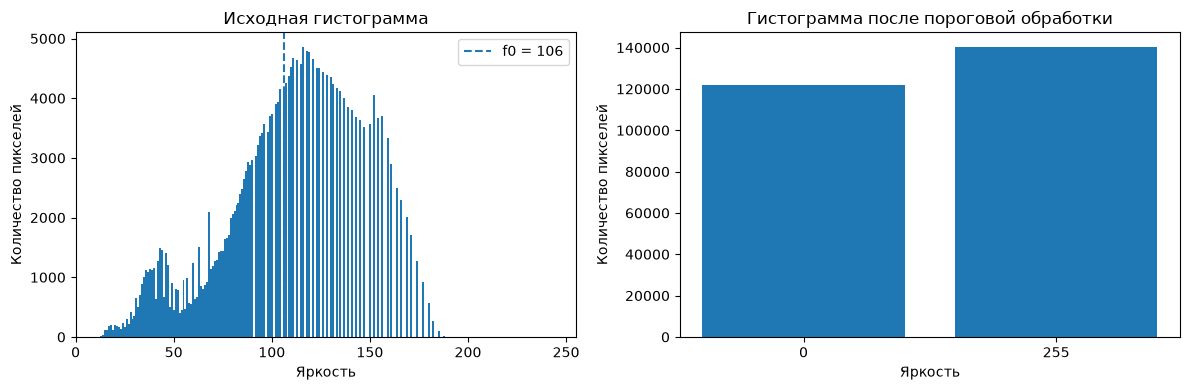

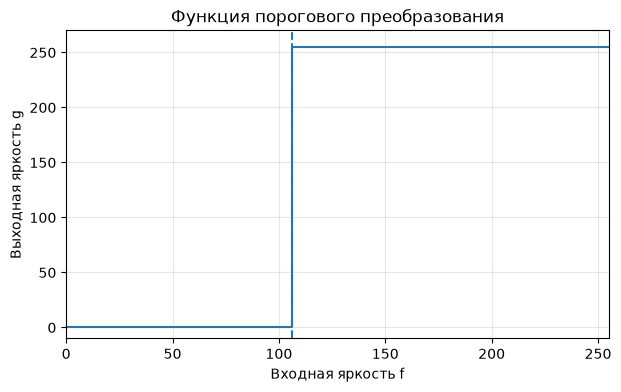

In [3]:
hist_bin, _ = np.histogram(binary.ravel(), bins=256, range=(0, 256))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].bar(np.arange(256), hist0, width=1)
ax[0].axvline(f0, linestyle="--", label=f"f0 = {f0}")
ax[0].set_xlim(0, 255)
ax[0].set_title("Исходная гистограмма")
ax[0].set_xlabel("Яркость")
ax[0].set_ylabel("Количество пикселей")
ax[0].legend()

# Для бинарного результата два уровня показываются явно
vals, nums = np.unique(binary, return_counts=True)
ax[1].bar(vals.astype(str), nums)
ax[1].set_title("Гистограмма после пороговой обработки")
ax[1].set_xlabel("Яркость")
ax[1].set_ylabel("Количество пикселей")

plt.tight_layout()
plt.show()

f = np.arange(256)
g_threshold = np.where(f >= f0, 255, 0)

plt.figure(figsize=(7, 4))
plt.step(f, g_threshold, where="post")
plt.axvline(f0, linestyle="--")
plt.xlim(0, 255)
plt.ylim(-10, 270)
plt.xlabel("Входная яркость f")
plt.ylabel("Выходная яркость g")
plt.title("Функция порогового преобразования")
plt.grid(alpha=0.3)
plt.show()

# II. Линейное контрастирование

## Линейное контрастирование

Определяются минимальная и максимальная яркости исходного изображения:

$$
f_{min}=\min(f), \qquad f_{max}=\max(f).
$$

Для растяжения исходного диапазона на `[0,255]` используется:

$$
g(f)=af+b,
$$

$$
a=\frac{255}{f_{max}-f_{min}}, \qquad b=-af_{min}.
$$

После преобразования минимальная яркость должна перейти примерно в 0, максимальная — в 255. Гистограмма при этом растягивается по оси яркости.

f_min = 12
f_max = 249
a = 1.0759493670886076
b = -12.91139240506329
Диапазон после: 0 - 255


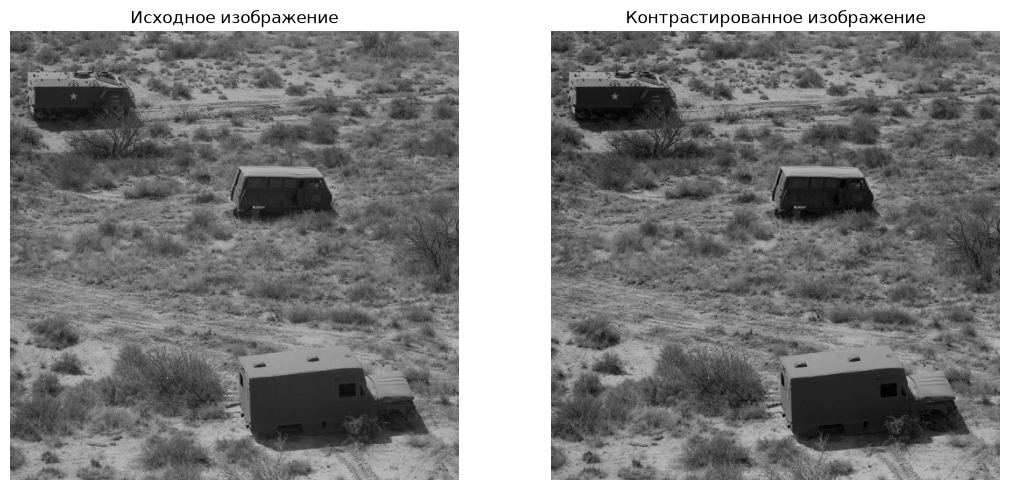

In [4]:
f_min = int(img.min())
f_max = int(img.max())

a = 255.0 / (f_max - f_min) if f_max != f_min else 1.0
b = -a * f_min

contrast = np.clip(a * img.astype(np.float64) + b, 0, 255).astype(np.uint8)

print("f_min =", f_min)
print("f_max =", f_max)
print("a =", a)
print("b =", b)
print("Диапазон после:", contrast.min(), "-", contrast.max())

fig, ax = plt.subplots(1, 2, figsize=(11, 5))

ax[0].imshow(img, cmap="gray", vmin=0, vmax=255)
ax[0].set_title("Исходное изображение")
ax[0].axis("off")

ax[1].imshow(contrast, cmap="gray", vmin=0, vmax=255)
ax[1].set_title("Контрастированное изображение")
ax[1].axis("off")

plt.tight_layout()
plt.show()

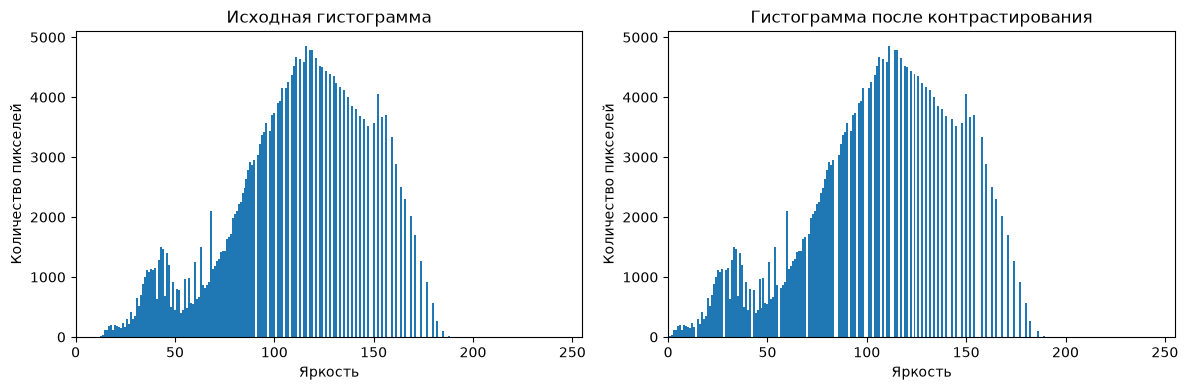

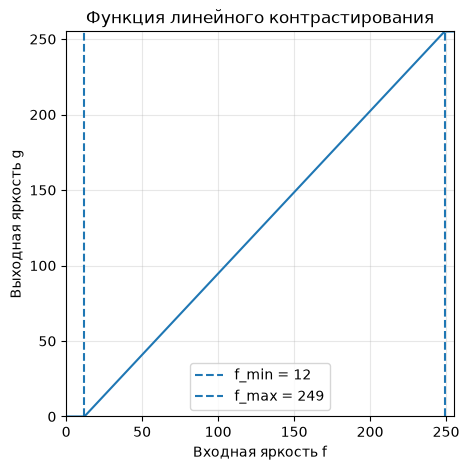

In [5]:
hist_before, _ = np.histogram(img.ravel(), bins=256, range=(0, 256))
hist_contrast, _ = np.histogram(contrast.ravel(), bins=256, range=(0, 256))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].bar(np.arange(256), hist_before, width=1)
ax[0].set_xlim(0, 255)
ax[0].set_title("Исходная гистограмма")
ax[0].set_xlabel("Яркость")
ax[0].set_ylabel("Количество пикселей")

ax[1].bar(np.arange(256), hist_contrast, width=1)
ax[1].set_xlim(0, 255)
ax[1].set_title("Гистограмма после контрастирования")
ax[1].set_xlabel("Яркость")
ax[1].set_ylabel("Количество пикселей")

plt.tight_layout()
plt.show()

f = np.arange(256)
g_contrast = np.clip(a * f + b, 0, 255)

plt.figure(figsize=(5, 5))
plt.plot(f, g_contrast)
plt.axvline(f_min, linestyle="--", label=f"f_min = {f_min}")
plt.axvline(f_max, linestyle="--", label=f"f_max = {f_max}")
plt.xlim(0, 255)
plt.ylim(0, 255)
plt.xlabel("Входная яркость f")
plt.ylabel("Выходная яркость g")
plt.title("Функция линейного контрастирования")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# III. Эквализация

In [6]:
# Гистограмма и границы интервалов
hist, bins = np.histogram(img.ravel(), bins=256, range=(0, 256))

print("hist =")
print(hist)

print("\nbins =")
print(bins)

print("\nНачало bins:", bins[:10])
print("Конец bins:", bins[-10:])
print("bins[0] =", bins[0])
print("bins[-1] =", bins[-1])

hist =
[   0    0    0    0    0    0    0    0    0    0    0    0    5   18
   40  113  119  177  192  116  205  188  160  141  237  172  303  217
  424  303  345  645  509  695  890  998 1118 1086 1138 1121 1154  628
 1280 1493 1460  677 1400 1201  501  912  446  800  789  394  450  961
  476  991  568  557 1246  640  662 1503  859  810  869  913 2101 1131
 1187 1265 1297 1424 1439 1433 1639 1665 1710 1989 2053 2102 2217 2252
 2402 2483 2639 2782 2925 2875 2957    0 3035 3224 3363 3424 3569    0
 3442 3706 3740    0 3899 3942 4154    0 4149 4252    0 4367 4517 4669
    0 4640    0 4581 4861    0 4795 4780    0 4649    0 4514 4508    0
 4441    0 4393    0 4356 4235    0 4172    0 4113    0 4011    0 3851
    0 3801    0 3687    0 3638    0 3520    0    0 3576    0 4051    0
 3670    0 3702    0    0 3331    0 2891    0    0 2500    0 2295    0
    0 2013    0 1702    0    0 1274    0    0  922    0    0  563    0
  267    0    0   96    0    0    8    0    0    0    0    0    0    1

## Эквализация

Интегральная функция распределения вычисляется суммой с накоплением:

$$
F(k)=\sum_{i=0}^{k}p(i).
$$

В коде для этого используется `np.cumsum`, то есть цикл не требуется.

Функция эквализации для диапазона 0–255:

$$
g(f)=255F_f(f).
$$

CDF является неубывающей, поэтому и функция преобразования `g(f)` также не убывает.

### Самописная и стандартная эквализация

Самописная эквализация строится из нормированной гистограммы и её CDF.

Стандартная функция `exposure.equalize_hist()` используется для визуального сравнения.

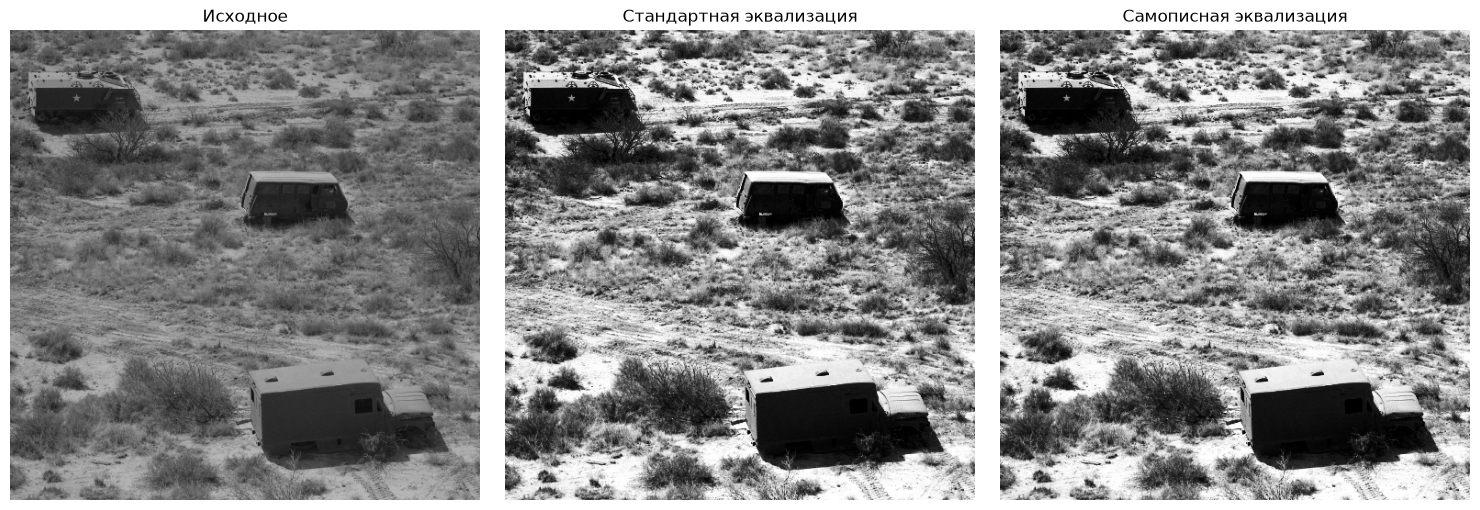

In [7]:
# Самописная эквализация
pdf = hist / hist.sum()
cdf = np.cumsum(pdf)
transform = np.round(255 * cdf).astype(np.uint8)

equal_manual = transform[img]

# Стандартная эквализация только для сравнения
equal_standard = exposure.equalize_hist(img)
equal_standard = np.round(equal_standard * 255).astype(np.uint8)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))

ax[0].imshow(img, cmap="gray", vmin=0, vmax=255)
ax[0].set_title("Исходное")
ax[0].axis("off")

ax[1].imshow(equal_standard, cmap="gray", vmin=0, vmax=255)
ax[1].set_title("Стандартная эквализация")
ax[1].axis("off")

ax[2].imshow(equal_manual, cmap="gray", vmin=0, vmax=255)
ax[2].set_title("Самописная эквализация")
ax[2].axis("off")

plt.tight_layout()
plt.show()

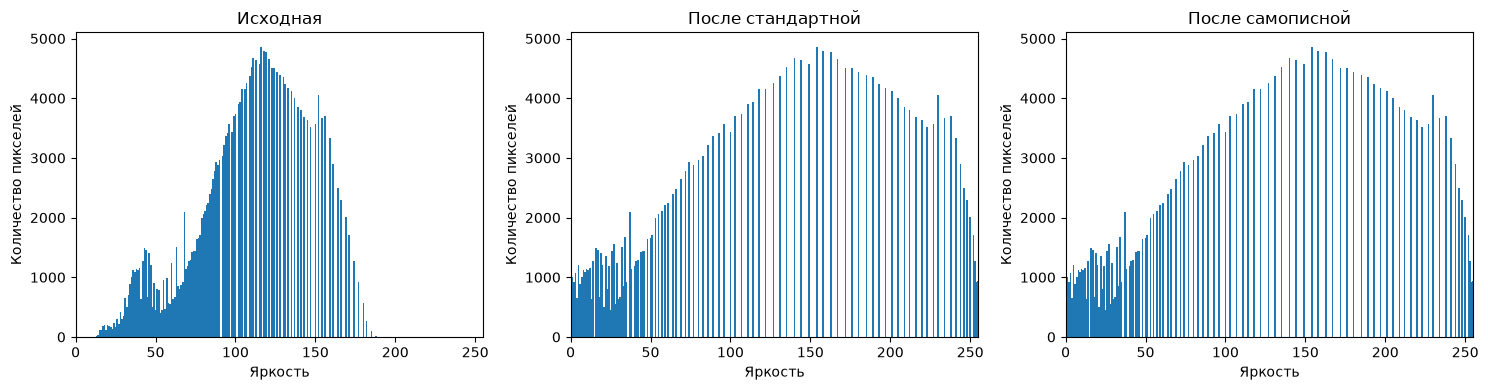

In [8]:
hist_standard, _ = np.histogram(equal_standard.ravel(), bins=256, range=(0, 256))
hist_manual, _ = np.histogram(equal_manual.ravel(), bins=256, range=(0, 256))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))

ax[0].bar(np.arange(256), hist, width=1)
ax[0].set_title("Исходная")
ax[0].set_xlim(0, 255)

ax[1].bar(np.arange(256), hist_standard, width=1)
ax[1].set_title("После стандартной")
ax[1].set_xlim(0, 255)

ax[2].bar(np.arange(256), hist_manual, width=1)
ax[2].set_title("После самописной")
ax[2].set_xlim(0, 255)

ax[0].set_xlabel("Яркость")
ax[0].set_ylabel("Количество пикселей")
ax[1].set_xlabel("Яркость")
ax[1].set_ylabel("Количество пикселей")
ax[2].set_xlabel("Яркость")
ax[2].set_ylabel("Количество пикселей")

plt.tight_layout()
plt.show()

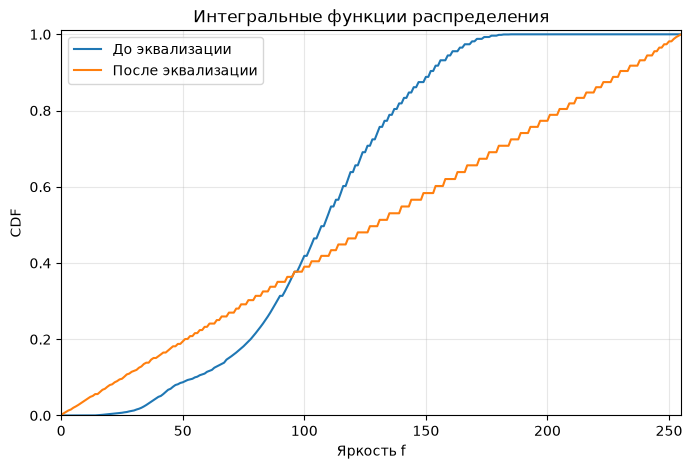

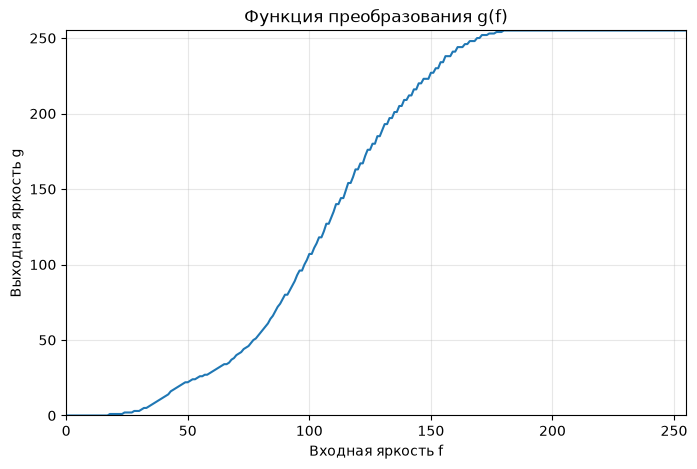

In [9]:
# Интегральные функции распределения до и после обработки
cdf_before = np.cumsum(hist / hist.sum())
cdf_after = np.cumsum(hist_manual / hist_manual.sum())

plt.figure(figsize=(8, 5))
plt.plot(np.arange(256), cdf_before, label="До эквализации")
plt.plot(np.arange(256), cdf_after, label="После эквализации")
plt.xlim(0, 255)
plt.ylim(0, 1.01)
plt.xlabel("Яркость f")
plt.ylabel("CDF")
plt.title("Интегральные функции распределения")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(np.arange(256), transform)
plt.xlim(0, 255)
plt.ylim(0, 255)
plt.xlabel("Входная яркость f")
plt.ylabel("Выходная яркость g")
plt.title("Функция преобразования g(f)")
plt.grid(alpha=0.3)
plt.show()

### Вывод по эквализации

**До преобразования:** яркости распределены неравномерно, а CDF имеет нелинейный вид.

**После преобразования:** уровни яркости перераспределены по доступному диапазону. CDF становится ближе к линейной, а детали изображения могут различаться лучше.

Самописный результат близок к стандартной эквализации, значит, самописная функция реализована корректно.